In [38]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.nn.functional import cross_entropy
%matplotlib inline

words = open('../names.txt', 'r').read().splitlines()  # 32033
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [39]:
block_size = 3


def build_dateset(words):
    X, Y = [], []

    for w in words:
        # fill 3 letters in x fill next in y
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)  # 0.0.0 on first iteration
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

# first we want to shuffle the words
# then we want 80% training set
# then we want 10% dev test
# then we want 10% final test

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

train_data = words[:n1]
dev_data = words[n1:n2]
test_data = words[n2:]

X_train, Y_train = build_dateset(train_data)
X_dev, Y_dev = build_dateset(dev_data)
X_test, Y_test = build_dateset(test_data)

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [40]:
# MLP revisited
n_embeddings = 10  # the dimensionality of the character embedding vectors
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
embeddings = torch.randn((vocab_size, n_embeddings), generator=g)      # torch.Size([27, 10])
W1 = torch.randn((n_embeddings * block_size, n_hidden), generator=g) * (5 / 3) / ((n_embeddings * block_size) ** 0.5)  # torch.Size([30,200])
b1 = torch.randn(n_hidden,                        generator=g) * 0      # torch.Size([200])
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.1  # torch.Size([200,27])
b2 = torch.randn(vocab_size,                      generator=g) * 0    # torch.Size([27,])

batch_normalization_gain = torch.ones((1, n_hidden)) # I ask about this
batch_normalization_bias = torch.zeros((1, n_hidden)) # I ask about this

parameters = [embeddings, W1, b1, W2, b2, batch_normalization_gain, batch_normalization_bias]

print(sum(p.nelement() for p in parameters))  # 11897
for p in parameters:
    p.requires_grad = True

12297


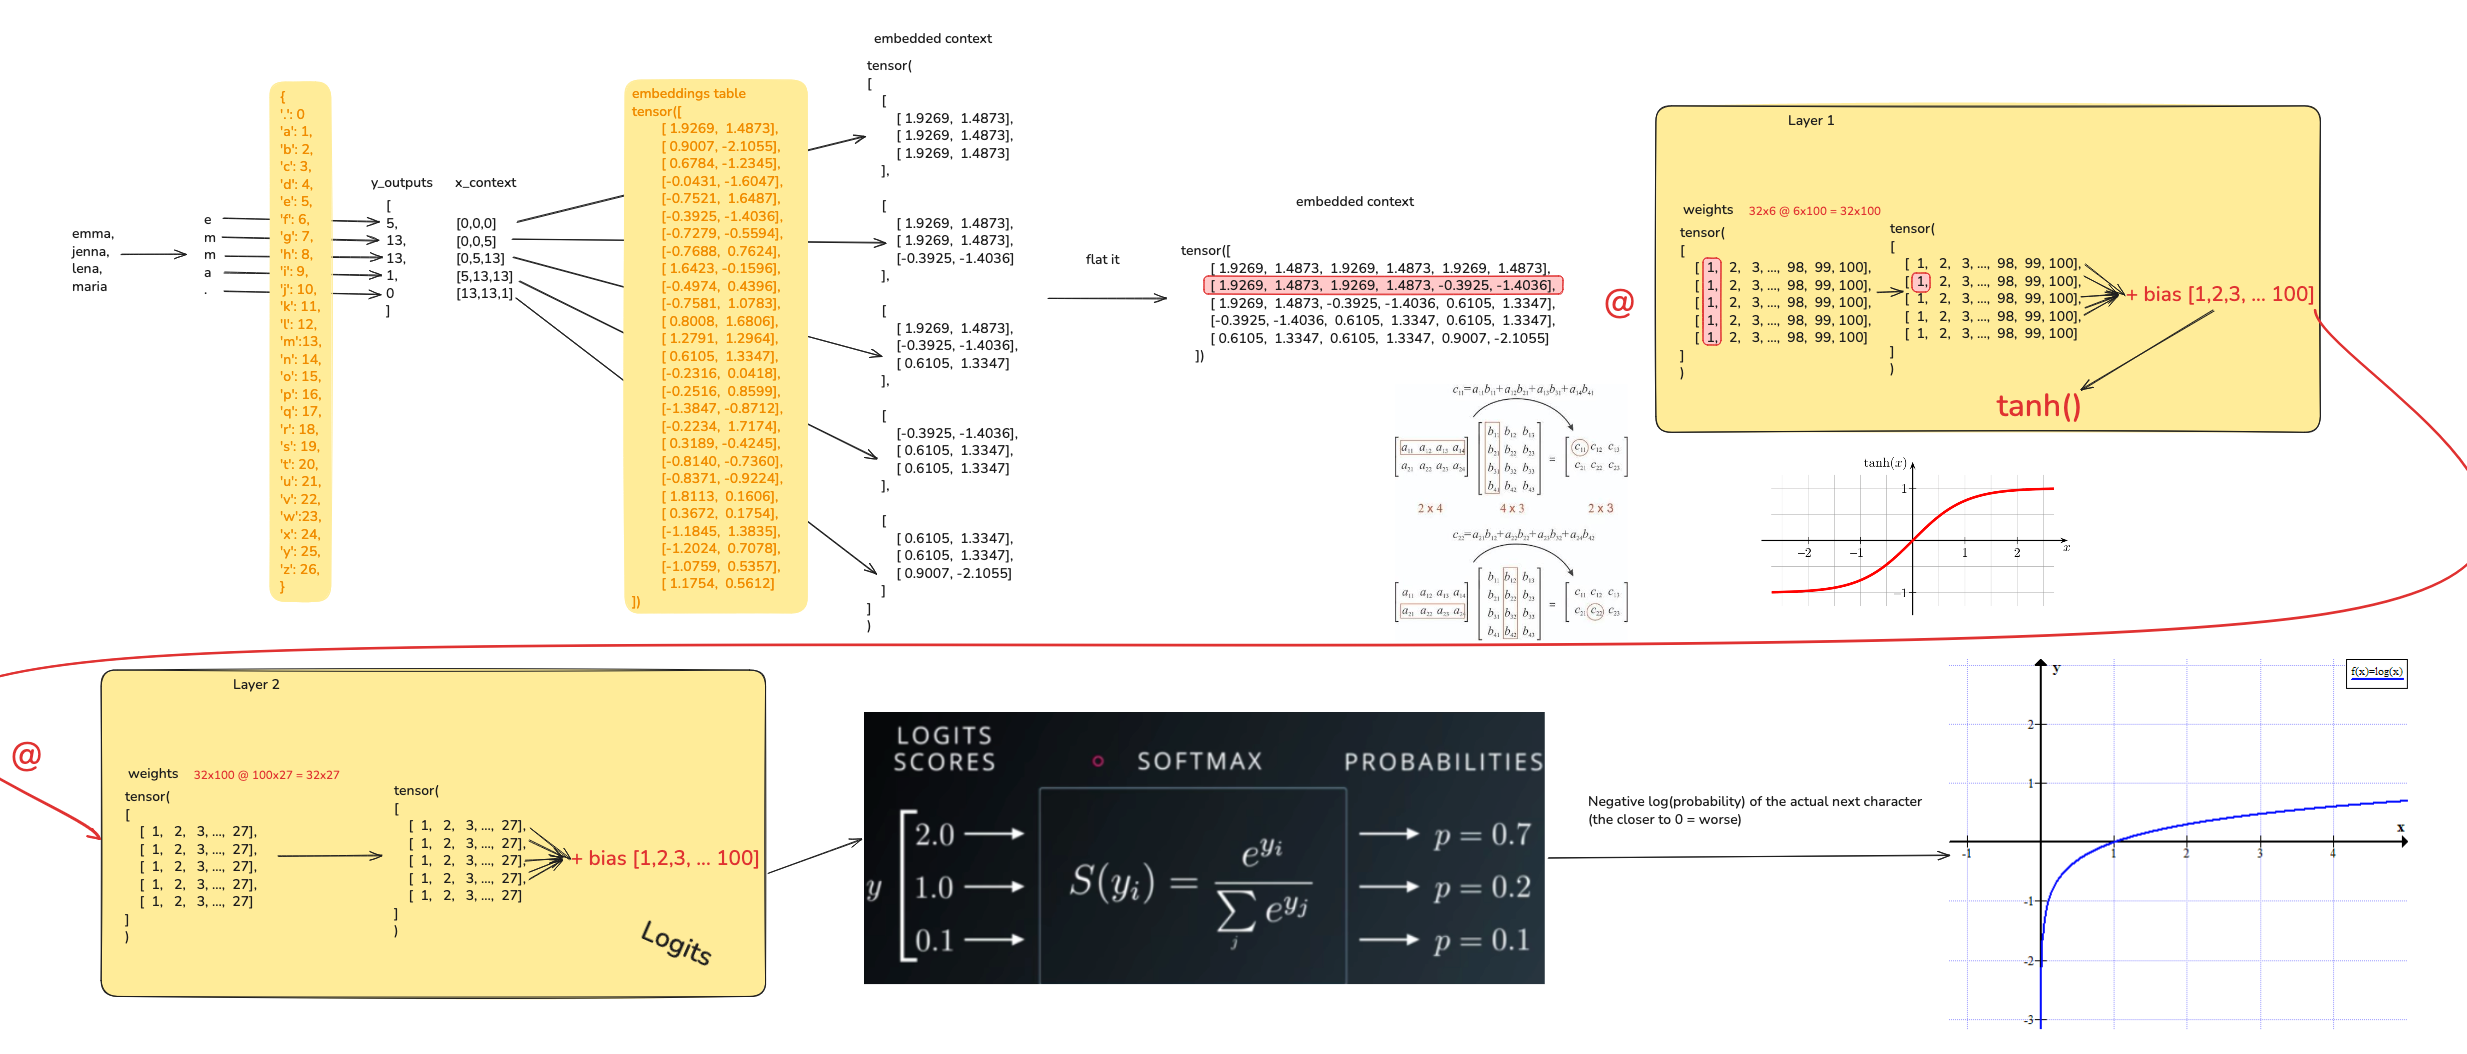

In [41]:
max_steps = 200_000
batch_size = 32
lossi = []

for i in range(200_000):

    ix = torch.randint(0, X_train.shape[0], (batch_size,), generator=g)
    X_batch, Y_batch = X_train[ix], Y_train[ix]  # batch X, Y

    #forward pass
    embedded_samples = embeddings[X_batch]  # 32 samples of context of 3 letters each embedded in 10 numbers
    embedded_concatenated_samples = embedded_samples.view(embedded_samples.shape[0], -1)  # concatenate the vectors
    hpreact = embedded_concatenated_samples @ W1 + b1
    hpreact = (batch_normalization_gain *
               (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0,keepdim=True)) + batch_normalization_bias # I ask about this
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y_batch)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.01 if i < 100_000 else 0.001
    for p in parameters:
        p.data += - lr * p.grad

    if i % 10_000 == 0:
        print(f'{i:7d} /{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    break;

      0 / 200000: 3.7900


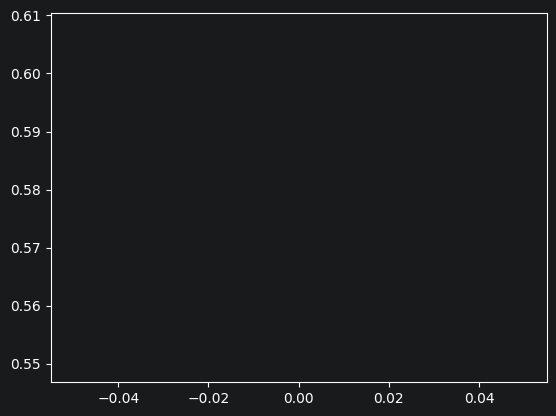

In [42]:
plt.plot(lossi)

In [43]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    # x, y = {'train': (Xtr, Ytr),
    #         'val': (Xdev, Ydev),
    #         'test': (Xtest, Ytest),
    #         }[split]

    if split == 'train':
        x, y = X_train, Y_train
    elif split == 'val':
        x, y = X_dev, Y_dev
    elif split == 'test':
        x, y = X_test, Y_test

    embedded_samples = embeddings[x] # (total entries, block_size, n_embd)
    embedded_concatenated_samples = embedded_samples.view(embedded_samples.shape[0],-1) # concat into (N, block_size)
    hpreact = embedded_concatenated_samples @ W1 + b1

    hpreact = (batch_normalization_gain *
               (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0,keepdim=True)) + batch_normalization_bias
    h = torch.tanh(hpreact) # (N, vocab_size)
    logits = h @ W2 + b2 # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 3.684223175048828
val 3.6812596321105957


In [44]:
g = torch.Generator().manual_seed(2147483647+10)

for _ in range(20):
    out = []
    context = [0]*block_size #initialize with all ...

    while True:
        embedded_samples = embeddings[torch.tensor([context])] # (1,block_size, n_embd)
        h = torch.tanh(embedded_samples.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        # shift the context window and track the samples
        context = context[1:]+[ix]
        out.append(ix)
        # if we sample the special '.' token, break
        if ix == 0:
            break

    print(''.join(itos[i] for i in out)) # decode and print the generated word


cbrpzvfqhoflqruhcjmrzxvthgjkhgcjysgejrrhuhjfbgksrrwpvgqhicoesmuipjcmmiirduxjeggpdzsmgpows.
qbgjtis.
ouxwaljiqbq.
wqxtlojdiaryxixfkcgkpigslxjef.
gpoip.
gtlsfwysfwyoapaemoukjrksyadimqqosozswplojn.
cokhifryodkpfzadlduodnoebsrksrauhrynhgaopllmtnraes.
xqholoqnpsbvbwdeyipvqmuitjgbvzmhpodgpycsvslqhkkrnu.
zfkkrynadfkhkbp.
skcthmzimdtevl.
ky.
q.
cctfouowoyttbjjohczftjcj.
zolndzse.
ku.
eoaigtkxerrqci.
kcfkyrbadiieluguyozwyysdyokhmlkfkkromcaddtxhvkoyndiwuwpxksxwymszxqpotzsik.
z.
rngpknbflntixsfwdkkjhfj.
kugkrvzhpvwbepodvkhhkxrnmttoscvnpgewjmjqfwjthgfwkewjdfxckxdytzvhgkpmytzl.


In [45]:
from torchviz import make_dot

make_dot(
    loss,
    params={'embeddings_table': embeddings, 'weights1': W1,
            'bias1': b1, 'weights2': W2, 'bias2': b2},
    show_attrs=True,
    show_saved=True,
    max_attr_chars=200,
)


RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.